In [ ]:
import pandas as pd
import ast
import geopandas as gpd
from shapely.geometry import LineString

# test data

In [ ]:
# if read move data from 3_RestorativePlace
df = pd.read_csv('../../raw/MBQ1/MBQ1_output_move.csv')
len(df)

In [ ]:
# if read row MBQ1 data from 3_RestorativePlace and extract move
df = pd.read_csv('../../raw/MBQ1/MBQ1_output_all.csv')

from __future__ import annotations
from pathlib import Path
import pandas as pd


def combine_mbq1_move_only(
    input_file: str = "../../raw/MBQ1/MBQ1_output_all.csv",
    output_file: str = "../../intermediate/MBQ1/MBQ1_output_move.csv",
) -> pd.DataFrame:
    """
    Read MBQ1_output_all.csv, keep only move rows, and save to MBQ1_output_move.csv.

    A row is kept if any of the following columns equals 'move':
        - type
        - stopType
        - detailedMoveType
    """
    in_file = Path(input_file)
    out_file = Path(output_file)

    if not in_file.exists():
        raise FileNotFoundError(f"Input file does not exist: {in_file}")

    out_file.parent.mkdir(parents=True, exist_ok=True)

    df = pd.read_csv(in_file)

    candidate_cols = ["type", "stopType", "detailedMoveType"]
    existing_cols = [c for c in candidate_cols if c in df.columns]

    if not existing_cols:
        raise ValueError(
            f"No move-type column found. Expected one of: {candidate_cols}"
        )

    mask = pd.Series(False, index=df.index)
    for col in existing_cols:
        mask = mask | df[col].astype(str).str.strip().eq("move")

    df_move = df[mask].copy()
    df_move.to_csv(out_file, index=False)

    print(f"[ok] Input file     : {in_file}")
    print(f"[ok] Output file    : {out_file}")
    print(f"[ok] Filter columns : {existing_cols}")
    print(f"[ok] Move rows      : {len(df_move)}")

    return df_move


if __name__ == "__main__":
    combine_mbq1_move_only()

# read data

In [ ]:
df = pd.read_csv('../../raw/MBQ1/MBQ1_output_move.csv')
len(df)

In [ ]:
df['skip_optional'].value_counts(dropna=False)

# filter - having traffic mode annotation

In [ ]:
df = df[~df['trafficMode'].isna()] # filled questionnaires
len(df) 

In [ ]:
df['skip_optional'].value_counts(dropna=False)

# filter - having ratings

In [ ]:
df = df[(df['restRating']>-1) & (df['alertRating']>-1) & (df['mindRating']>-1)] # fully filled questionnaires
len(df)

# filter - walking

In [ ]:
df['trafficMode'].unique()

In [ ]:
df['trafficMode_other'].unique()

In [ ]:
df_mix = df[df['trafficMode_other'].str.contains('Fuss', na=False)]
print(len(df_mix))
print(df_mix['PID'].nunique())

In [ ]:
df = df[df['trafficMode'] == 'Zu Fuss']
print(len(df))
print(df['PID'].nunique())

In [ ]:
# KEEP RECORD
# df['trafficMode'].value_counts()

# Zu Fuss    1705
# Velo        222
# E-Bike      122
# Name: trafficMode, dtype: int64

# filter - May-September

In [ ]:
df['timeStart'] = pd.to_datetime(df['timeStart'])
df['timeEnd'] = pd.to_datetime(df['timeEnd'])

df['duration'] = df['timeEnd'] - df['timeStart']
df['duration_s'] = (df['timeEnd'] - df['timeStart']).dt.total_seconds()

# 2. Filter records from 2024
mask_2024 = df['timeStart'].dt.year == 2024
df_2024 = df.loc[mask_2024, 'timeStart']

# 3. Calculate the minimum and maximum
min_2024 = df_2024.min()
max_2024 = df_2024.max()

print(f"2024 min: {min_2024}")
print(f"2024 max: {max_2024}")

# 2. Filter records from 2025
mask_2025 = df['timeStart'].dt.year == 2025
df_2025 = df.loc[mask_2025, 'timeStart']

# 3. Calculate the minimum and maximum
min_2025 = df_2025.min()
max_2025 = df_2025.max()

print(f"2024 min: {min_2025}")
print(f"2024 max: {max_2025}")

df = df[df['timeStart'].dt.month.isin([4, 5, 6, 7, 8, 9,10])].copy()
print(len(df))
print(df['PID'].nunique())

# filter - duration

In [ ]:
print(df['duration_s'].describe())
df = df[df['duration_s']>3*60]
print(len(df))
print(df['PID'].nunique())

# filter - within Switzerland

In [ ]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import LineString
import ast

# 1. Convert string representations of lists to lists
def safe_eval(x):
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return None
    return x

df['path_coords'] = df['path_coords'].apply(safe_eval)

# 2. Keep only paths that can form a LineString (at least 2 points)
# Exclude None and lists with fewer than 2 points
df = df[df['path_coords'].notna()]
df = df[df['path_coords'].apply(len) >= 2]

# 3. Create geometries by switching coordinate order ([lat, lon] -> (lon, lat))
df['geometry'] = df['path_coords'].apply(lambda x: LineString([(c[1], c[0]) for c in x]))

# 4. Convert to a GeoDataFrame and reproject it
gdf = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")
gdf = gdf.to_crs("EPSG:2056")

# 5. Load the boundary (gpd.read_file usually reads the CRS automatically)
boundary = gpd.read_file('../../raw/SwitzerlandBoundary.geojson')
# Reproject the boundary if its CRS differs from EPSG:2056
if boundary.crs != "EPSG:2056":
    boundary = boundary.to_crs("EPSG:2056")

# 6. Keep the parts of paths within the boundary
# clip trims paths at the boundary, while sjoin with the within predicate keeps whole paths inside it
gdf_final = gpd.clip(gdf, boundary)


In [ ]:
# gdf_final

# column - rating compute

In [ ]:
gdf_final.columns

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

gdf_final['Rating'] = (gdf_final['restRating'] + gdf_final['alertRating'] + gdf_final['mindRating'])/3

gdf_final['Rating'] = np.floor(gdf_final['Rating'] * 100) / 100

# column - persensPresent code

In [ ]:
import ast
import pandas as pd

gdf_final['personsPresent'] = gdf_final['personsPresent'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else []
)

dummies = (
    gdf_final['personsPresent']
    .explode()
    .str.get_dummies()
    .groupby(level=0)
    .max()
)

rename_map = {
    'Andere': 'pp_other',
    'Bekannte / Kollegen/innen': 'pp_acquaintances_colleagues',
    'Familie': 'pp_family',
    'Fremde': 'pp_strangers',
    'Freunde/innen': 'pp_friends',
    'Ich war allein': 'pp_alone',
    'Partner/in': 'pp_partner'
}

dummies = dummies.rename(columns=rename_map)

gdf_final = gdf_final.join(dummies)

print(dummies.columns.tolist())
print(gdf_final.head())

In [ ]:
gdf_final.columns

# column - selection

In [ ]:
gdf_final = gdf_final[['PID','timeEnd', 'timeStart','secondActivity', 'secondActivity_other',
                       'duration_s',
       'geometry', 'Rating', 'pp_other', 'pp_acquaintances_colleagues',
       'pp_family', 'pp_strangers', 'pp_friends', 'pp_alone', 'pp_partner']]

In [ ]:
gdf_final = gdf_final.reset_index()
gdf_final = gdf_final.rename(columns = {'index':'trip_id'})

# dataset saving

In [ ]:
gdf_final.to_file("../../intermediate/active_move_respond_CH.geojson", driver='GeoJSON')

In [ ]:
gdf_final = gpd.read_file("../../intermediate/active_move_respond_CH.geojson")

# variable distribution

In [ ]:
gdf_final['PID'].value_counts().describe()

<Axes: >

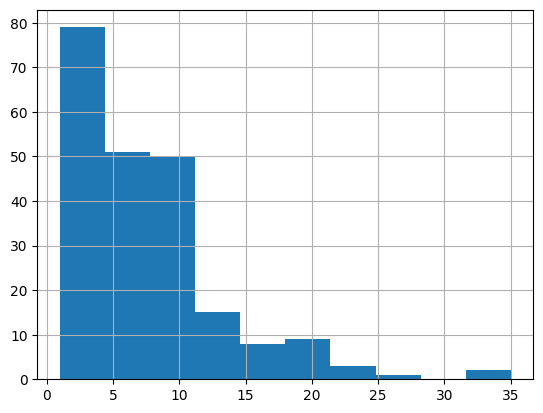

In [ ]:
gdf_final['PID'].value_counts().hist()

In [ ]:
sns.countplot(x=gdf_final['Rating'])

plt.xticks(rotation=45) 

plt.title('Frequency of Each Rating Category')
plt.show()

<Axes: >

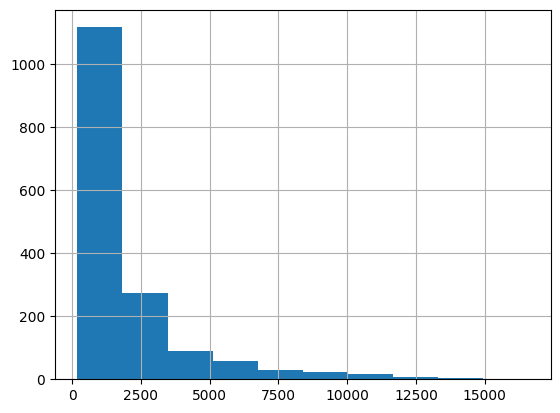

In [ ]:
gdf_final['duration_s'].hist()

<Axes: >

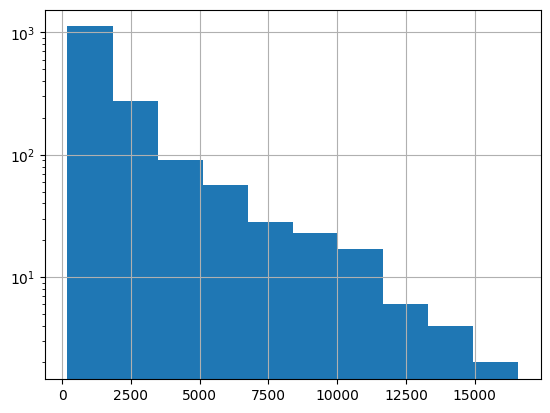

In [ ]:
gdf_final['duration_s'].hist(log=True)

In [ ]:
gdf_final['duration_s'].describe()

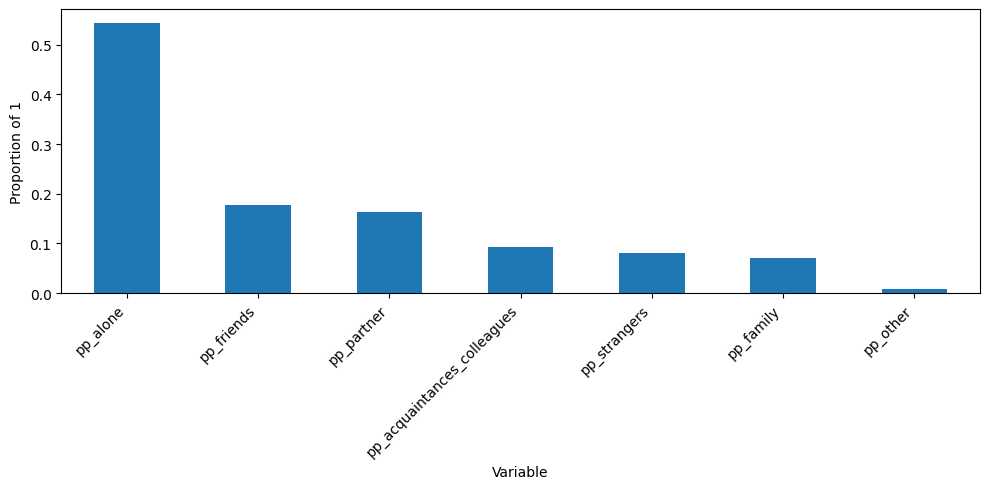

In [ ]:
import matplotlib.pyplot as plt

cols = [
    'pp_other',
    'pp_acquaintances_colleagues',
    'pp_family',
    'pp_strangers',
    'pp_friends',
    'pp_alone',
    'pp_partner'
]

prop = gdf_final[cols].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
prop.plot(kind='bar')
plt.ylabel('Proportion of 1')
plt.xlabel('Variable')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
gdf_final.columns

In [ ]:
import pandas as pd

cols_check = [
    'pp_other',
    'pp_acquaintances_colleagues',
    'pp_family',
    'pp_strangers',
    'pp_friends',
    'pp_partner'
]


df_alone = gdf_final[gdf_final['pp_alone'] == 1].copy()

count_1 = (df_alone[cols_check] == 1).sum()

prop_1 = (df_alone[cols_check] == 1).mean()

summary = pd.DataFrame({
    'count_1': count_1,
    'prop_1': prop_1,
    'percent_1': prop_1 * 100
}).sort_values('count_1', ascending=False)

print("pp_alone == 1 的总行数：", len(df_alone))
print(summary)